# Uber for Business → Contas a Pagar — análise de julho e agosto/2026

Fonte: `output/canonical.duckdb`, gerado por `run.py`, e `reconciliation/`, gerado por `bank_reconciliation.py`.
Todas as tabelas são consultas a esses resultados. Os `assert` param a execução se algum total deixar de amarrar.

In [1]:
import json
from decimal import Decimal
from pathlib import Path

import duckdb
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import HTML, display
from matplotlib.backends.backend_pdf import PdfPages

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "run.py").exists())
con = duckdb.connect(str(ROOT / "output" / "canonical.duckdb"), read_only=True)
RUN = json.loads((ROOT / "output" / "run_summary.json").read_text(encoding="utf-8"))
BANK = (ROOT / "reconciliation" / "bank_reconciliation.csv").as_posix()

def q(sql):
    return con.sql(sql).df()

def one(sql):
    return con.sql(sql).fetchone()[0]

def brl(v):
    if v is None or pd.isna(v):
        return "—"
    return f"R$ {v:,.2f}".replace(",", "X").replace(".", ",").replace("X", ".")

_tabela = 0

def pct_br(v, sinal=False):
    return (f"{v:+.1%}" if sinal else f"{v:.1%}").replace(".", ",")

def show(df, money=(), pct=()):
    fmt = {c: brl for c in money} | {c: pct_br for c in pct}
    global _tabela
    _tabela += 1  # id fixo: o HTML salvo no notebook não muda entre execuções
    return HTML(df.style.set_uuid(f"t{_tabela}").format(fmt, na_rep="—").hide(axis="index").to_html())

BLUE, ORANGE, INK, MUTED, SURFACE = "#2a78d6", "#eb6834", "#0b0b0b", "#898781", "#fcfcfb"
plt.rcParams.update({"figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "axes.edgecolor": MUTED,
                     "text.color": INK, "axes.labelcolor": INK, "xtick.color": MUTED, "ytick.color": INK,
                     "axes.spines.top": False, "axes.spines.right": False, "font.size": 9,
                     "text.parse_math": False})

ROTA = {"company_billed": "Faturado Uber (boleto)",
        "employee_reimbursement_candidate": "Reembolso ao colaborador",
        "excluded_corporate_card_statement": "AMEX corporativo (processo próprio)",
        "needs_client_card_destination": "VISA corporativo (destino a definir)"}
print(f"Data-base {RUN['as_of_date']} · primeira competência automatizada {RUN['first_automated_competence']}")

Data-base 2026-09-28 · primeira competência automatizada 2026-09


## 1. Da origem ao valor conhecido

In [2]:
populacao = q("""
select (select count(*) from raw_uber_occurrences) as linhas_nos_relatorios,
       (select count(*) from int_transactions) as transacoes_unicas,
       (select count(*) from int_transactions where key_status = 'equivalent') as repetidas_entre_relatorios,
       (select count(*) from int_transaction_conflicts) as em_conflito,
       (select count(*) from int_transactions where amount_status <> 'known') as sem_valor_em_brl
""")
rotas = q("""
select payment_route_status as rota, count(*) as transacoes,
       sum(amount_brl) filter (where amount_status = 'known') as brl_conhecido,
       count(*) filter (where amount_status <> 'known') as sem_valor
from int_transaction_enrichment group by 1 order by brl_conhecido desc
""")
rotas["rota"] = rotas["rota"].map(ROTA).fillna(rotas["rota"])
total_conhecido = one("select sum(amount_brl) from int_transactions where amount_status = 'known'")
assert one("select sum(amount_brl) filter (where amount_status = 'known') from int_transaction_enrichment") == total_conhecido
assert rotas.transacoes.sum() == populacao.transacoes_unicas[0]
display(show(populacao))
display(show(rotas, money=["brl_conhecido"]))
print("Total com valor conhecido:", brl(total_conhecido), "· valores sem BRL não entram como zero")

linhas_nos_relatorios,transacoes_unicas,repetidas_entre_relatorios,em_conflito,sem_valor_em_brl
588,573,13,2,3


rota,transacoes,brl_conhecido,sem_valor
Faturado Uber (boleto),521,"R$ 29.318,23",3
Reembolso ao colaborador,39,"R$ 1.608,75",0
AMEX corporativo (processo próprio),12,"R$ 882,55",0
VISA corporativo (destino a definir),1,"R$ 33,20",0


Total com valor conhecido: R$ 31.842,73 · valores sem BRL não entram como zero


## 2. Onde está o gasto faturado

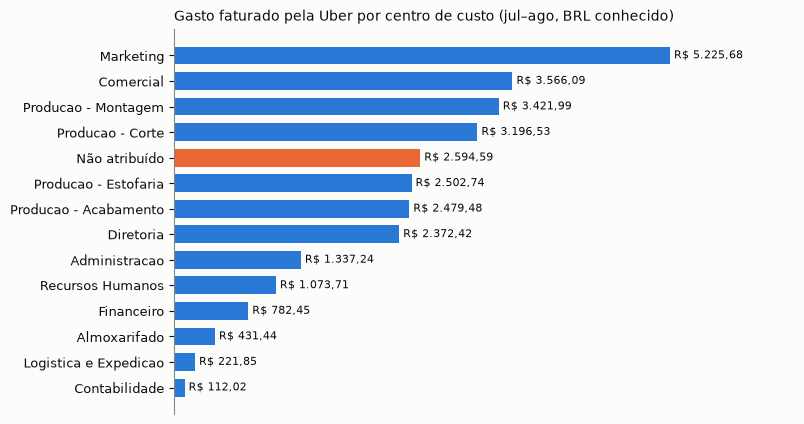

cc,nome,transacoes,brl,participacao
CC310,Marketing,116,"R$ 5.225,68","17,8%"
CC300,Comercial,79,"R$ 3.566,09","12,2%"
CC210,Producao - Montagem,53,"R$ 3.421,99","11,7%"
CC200,Producao - Corte,49,"R$ 3.196,53","10,9%"
UNATTRIBUTED,Não atribuído,41,"R$ 2.594,59","8,8%"
CC230,Producao - Estofaria,37,"R$ 2.502,74","8,5%"
CC220,Producao - Acabamento,34,"R$ 2.479,48","8,5%"
CC101,Diretoria,31,"R$ 2.372,42","8,1%"
CC100,Administracao,28,"R$ 1.337,24","4,6%"
CC120,Recursos Humanos,21,"R$ 1.073,71","3,7%"


In [3]:
faturado = one("select sum(amount_brl) from int_transaction_enrichment where payment_route_status = 'company_billed' and amount_status = 'known'")
cc = q("""
select s.cost_center as cc, coalesce(r.nome, 'Não atribuído') as nome,
       sum(s.candidate_count)::int as transacoes, sum(s.known_brl_subtotal) as brl
from int_monthly_cost_center_payment_summary s
left join (select cost_center, min(description) as nome from raw_ref_cost_centers group by 1) r using (cost_center)
where s.payment_route = 'company_billed'
group by all order by brl desc
""")
cc["participacao"] = cc.brl / cc.brl.sum()
assert one("select sum(known_brl_subtotal) from int_monthly_cost_center_payment_summary where payment_route = 'company_billed'") == faturado

def grafico_cc(ax):
    d = cc.sort_values("brl")
    labels = list(d.nome)
    colors = [ORANGE if c == "UNATTRIBUTED" else BLUE for c in d.cc]
    ax.barh(labels, d.brl, color=colors, height=0.7)
    for y, v in enumerate(d.brl):
        ax.text(v, y, " " + brl(v), va="center", fontsize=8, color=INK)
    ax.set_xlim(0, d.brl.max() * 1.25)
    ax.xaxis.set_visible(False)
    ax.spines["bottom"].set_visible(False)
    ax.set_title("Gasto faturado pela Uber por centro de custo (jul–ago, BRL conhecido)", loc="left", fontsize=10)

fig, ax = plt.subplots(figsize=(8, 5))
grafico_cc(ax)
plt.show()
display(show(cc, money=["brl"], pct=["participacao"]))

In [4]:
nao_atribuido = q("""
select case when transaction_type = 'Admin Fee' then 'Taxa administrativa (sem usuário)'
            when email_link_status = 'not_found' then 'E-mail sem cadastro no diretório'
            when email_link_status = 'ambiguous' then 'E-mail ligado a mais de uma pessoa'
            when official_cost_center_status = 'cost_center_not_found' then 'Centro de custo inexistente'
            when official_cost_center_status = 'cost_center_inactive' then 'Centro de custo inativo'
            else 'Outro' end as motivo,
       count(*) as transacoes,
       sum(amount_brl) filter (where amount_status = 'known' and not is_quarantined) as brl
from int_transaction_enrichment
where payment_route_status = 'company_billed' and official_cost_center_status is distinct from 'active'
group by 1 order by brl desc
""")
assert Decimal(str(round(nao_atribuido.brl.sum(), 2))) == Decimal(str(round(cc.loc[cc.cc == "UNATTRIBUTED", "brl"].sum(), 2)))
display(show(nao_atribuido, money=["brl"]))

motivo,transacoes,brl
E-mail sem cadastro no diretório,21,"R$ 1.370,82"
E-mail ligado a mais de uma pessoa,10,"R$ 442,15"
Taxa administrativa (sem usuário),2,"R$ 298,00"
Centro de custo inativo,4,"R$ 273,92"
Centro de custo inexistente,4,"R$ 209,70"


In [5]:
uso = q("""
select coalesce(nullif(service, '--'), 'Taxa administrativa') as tipo_de_uso, count(*) as transacoes,
       sum(amount_brl) filter (where amount_status = 'known') as brl
from int_transaction_enrichment where payment_route_status = 'company_billed' group by 1 order by brl desc
""")
movimento = q("""
select transaction_type as tipo_de_movimento, count(*) as transacoes,
       sum(amount_brl) filter (where amount_status = 'known') as brl
from int_transaction_enrichment where payment_route_status = 'company_billed' group by 1 order by brl desc
""")
display(show(uso, money=["brl"]), show(movimento, money=["brl"]))

tipo_de_uso,transacoes,brl
Travel | UberX,364,"R$ 19.877,14"
Eats,75,"R$ 4.148,66"
Travel | Black,33,"R$ 2.610,84"
Travel | Comfort,47,"R$ 2.383,59"
Taxa administrativa,2,"R$ 298,00"


tipo_de_movimento,transacoes,brl
Fare,494,"R$ 29.475,04"
Admin Fee,2,"R$ 298,00"
Tip,10,"R$ 39,00"
Adjustment,15,"R$ -493,81"


## 3. Evolução mensal

In [6]:
mensal = q("""
select payment_route as rota, reporting_month as mes, sum(known_brl_subtotal) as brl,
       sum(missing_amount_count + disputed_amount_count + parse_failed_amount_count) as sem_valor
from int_monthly_cost_center_payment_summary group by all
""")
mensal["rota"] = mensal["rota"].map(ROTA).fillna(mensal["rota"])
tabela = mensal.pivot_table(index="rota", columns="mes", values="brl", aggfunc="sum").reset_index()
sem_valor = mensal.pivot_table(index="rota", columns="mes", values="sem_valor", aggfunc="sum")
meses = sorted(mensal.mes.unique())
display(show(tabela, money=meses))
fat = tabela.set_index("rota").loc[ROTA["company_billed"]]
print(f"Faturado {meses[0]} → {meses[-1]}: {pct_br(fat[meses[-1]] / fat[meses[0]] - 1, sinal=True)}; itens sem valor por mês: "
      + ", ".join(f"{m} = {int(sem_valor.loc[ROTA['company_billed'], m])}" for m in meses)
      + ". A variação é do valor conhecido, não do total devido.")

rota,2026-07,2026-08
AMEX corporativo (processo próprio),"R$ 373,85","R$ 508,70"
Faturado Uber (boleto),"R$ 14.409,24","R$ 14.908,99"
Reembolso ao colaborador,"R$ 697,58","R$ 911,17"
VISA corporativo (destino a definir),"R$ 33,20",—


Faturado 2026-07 → 2026-08: +3,5%; itens sem valor por mês: 2026-07 = 2, 2026-08 = 1. A variação é do valor conhecido, não do total devido.


## 4. Faturas: demonstrativo × detalhe × banco

In [7]:
faturas = q(f"""
select r.competence as competencia, r.statement_total as documento,
       r.known_charges + r.known_fees as detalhe_conhecido,
       r.charge_residual + r.fee_residual as diferenca_sem_detalhe,
       r.unknown_charge_count as itens_sem_valor,
       try_cast(b.valor_pagamento_principal as decimal(15,2)) as pago_no_banco,
       try_cast(b.diferenca_pagamento_principal as decimal(15,2)) as pago_menos_documento
from int_statement_detail_reconciliation r
left join read_csv('{BANK}', all_varchar = true) b on b.id_externo = r.id_externo
order by 1
""")
assert one("select count(*) from stg_uber_statements where user_charges + service_fees <> statement_total") == 0
assert one("select sum(valor_total_candidato) from int_ap_release_gate where tipo = 'FATURA_FORNECEDOR'") == Decimal(str(round(faturas.documento.sum(), 2)))
assert Decimal(str(round(faturas.detalhe_conhecido.sum(), 2))) == faturado
display(show(faturas, money=["documento", "detalhe_conhecido", "diferenca_sem_detalhe", "pago_no_banco", "pago_menos_documento"]))

competencia,documento,detalhe_conhecido,diferenca_sem_detalhe,itens_sem_valor,pago_no_banco,pago_menos_documento
2026-07,"R$ 14.519,26","R$ 14.409,24","R$ 110,02",2,"R$ 14.519,26","R$ 0,00"
2026-08,"R$ 15.013,55","R$ 14.908,99","R$ 104,56",1,"R$ 15.318,82","R$ 305,27"


## 5. Reembolsos × extrato

In [8]:
SITUACAO = {"matched_exact": "Pago (valor exato)", "matched_aggregate": "Pago (PIX com dois meses)",
            "matched_with_difference": "Pago com diferença", "paid_more_than_once": "Pago em duplicidade",
            "open_as_of_statement_end": "Sem pagamento no extrato"}
reemb = q(f"""
select beneficiario, competencia,
       cast(valor_titulo as decimal(15,2)) as titulo,
       try_cast(valor_pagamento_principal as decimal(15,2)) as pago,
       try_cast(nullif(valor_pagamento_duplicado, '0.00') as decimal(15,2)) as pago_em_dobro,
       status, contains(bloqueios_ap, 'cpf') as cpf_invalido
from read_csv('{BANK}', all_varchar = true)
where tipo = 'REEMBOLSO_COLABORADOR' order by competencia, beneficiario
""")
reemb["situacao"] = reemb.status.map(SITUACAO).fillna(reemb.status)
reemb.loc[reemb.cpf_invalido, "situacao"] += " · CPF inválido"
assert one("select sum(valor_total_candidato) from int_ap_release_gate where tipo = 'REEMBOLSO_COLABORADOR'") == Decimal(str(round(reemb.titulo.sum(), 2)))
resumo_reemb = reemb.groupby("situacao", as_index=False).agg(titulos=("titulo", "size"), valor=("titulo", "sum"), pago=("pago", "sum"), em_dobro=("pago_em_dobro", "sum"))
display(show(resumo_reemb, money=["valor", "pago", "em_dobro"]))
display(show(reemb.drop(columns=["status", "cpf_invalido"]), money=["titulo", "pago", "pago_em_dobro"]))

situacao,titulos,valor,pago,em_dobro
Pago (PIX com dois meses),2,"R$ 110,40","R$ 110,40","R$ 0,00"
Pago (valor exato),11,"R$ 917,56","R$ 917,56","R$ 0,00"
Pago com diferença,1,"R$ 115,30","R$ 115,29","R$ 0,00"
Pago em duplicidade,1,"R$ 73,78","R$ 73,78","R$ 73,78"
Sem pagamento no extrato,1,"R$ 146,23","R$ 0,00","R$ 0,00"
Sem pagamento no extrato · CPF inválido,2,"R$ 245,48","R$ 0,00","R$ 0,00"


beneficiario,competencia,titulo,pago,pago_em_dobro,situacao
Andre Fonseca Filho,2026-07,"R$ 61,89","R$ 61,89",—,Pago (valor exato)
Andre Fonseca Moraes,2026-07,"R$ 37,37","R$ 37,37",—,Pago (PIX com dois meses)
Andre Fonseca Neto,2026-07,"R$ 146,23",—,—,Sem pagamento no extrato
Bianca Azevedo da Silva,2026-07,"R$ 63,73","R$ 63,73",—,Pago (valor exato)
Eduardo Batista Moraes,2026-07,"R$ 76,97","R$ 76,97",—,Pago (valor exato)
Eduardo Batista da Silva,2026-07,"R$ 94,93","R$ 94,93",—,Pago (valor exato)
Marcos Tavares,2026-07,"R$ 73,78","R$ 73,78","R$ 73,78",Pago em duplicidade
Mariana Lopes da Silva,2026-07,"R$ 142,68",—,—,Sem pagamento no extrato · CPF inválido
Andre Fonseca Filho,2026-08,"R$ 40,79","R$ 40,79",—,Pago (valor exato)
Andre Fonseca Moraes,2026-08,"R$ 73,03","R$ 73,03",—,Pago (PIX com dois meses)


## 6. O que falta para ratear a fatura

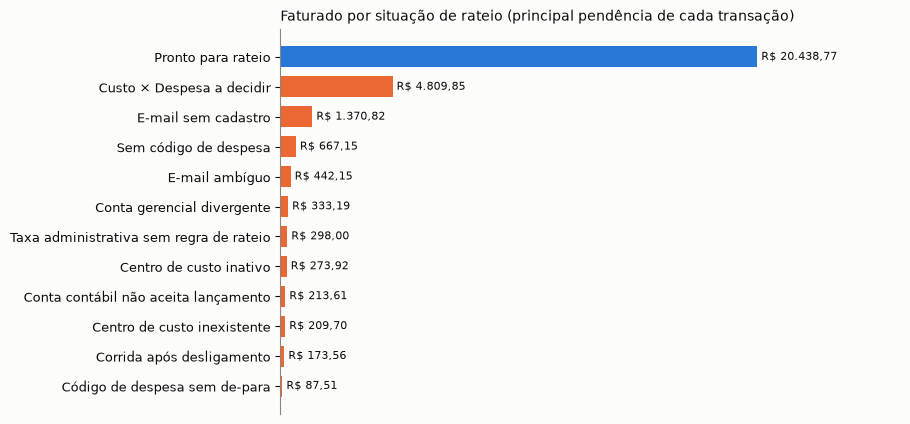

causa,transacoes,brl,codigos,participacao
Pronto para rateio,373,"R$ 20.438,77","ADM, AERO, ENTRE-UN, HE-REF, VIS-CLI","69,7%"
Custo × Despesa a decidir,73,"R$ 4.809,85","ENTRE-UN, TRANSP-FUNC","16,4%"
E-mail sem cadastro,21,"R$ 1.370,82","ADM, AERO, ENTRE-UN, HE-REF, TRANSP-FUNC, TREIN","4,7%"
Sem código de despesa,11,"R$ 667,15",—,"2,3%"
E-mail ambíguo,10,"R$ 442,15","ADM, VIS-CLI","1,5%"
Conta gerencial divergente,10,"R$ 333,19",EVENTO,"1,1%"
Taxa administrativa sem regra de rateio,2,"R$ 298,00",—,"1,0%"
Centro de custo inativo,4,"R$ 273,92",TRANSP-FUNC,"0,9%"
Conta contábil não aceita lançamento,5,"R$ 213,61",TREIN,"0,7%"
Centro de custo inexistente,4,"R$ 209,70",ADM,"0,7%"


In [9]:
CAUSA = {"candidate_for_stage3_review": "Pronto para rateio",
         "cost_expense_classification_pending": "Custo × Despesa a decidir",
         "not_found": "E-mail sem cadastro", "ambiguous": "E-mail ambíguo",
         "missing_expense_code": "Sem código de despesa", "unmapped_expense_code": "Código de despesa sem de-para",
         "expense_classification_suggestion_disagreement": "Conta gerencial divergente",
         "account_not_postable": "Conta contábil não aceita lançamento",
         "admin_fee_allocation_rule_pending": "Taxa administrativa sem regra de rateio",
         "cost_center_inactive": "Centro de custo inativo", "cost_center_not_found": "Centro de custo inexistente",
         "ride_after_termination": "Corrida após desligamento",
         "financial_amount_not_known": "Sem valor em BRL", "canonical_candidate_retained": "Valores em conflito entre relatórios"}
causas = q("""
select stage3_financial_gate as causa, count(*) as transacoes, sum(amount_brl) as brl,
       string_agg(distinct expense_code, ', ' order by expense_code) as codigos
from int_ap_component_candidates where payment_route_status = 'company_billed'
group by 1 order by brl desc nulls last
""")
causas["causa"] = causas.causa.map(CAUSA).fillna(causas.causa)
causas["participacao"] = causas.brl / causas.brl.sum()
assert Decimal(str(round(causas.brl.sum(), 2))) == faturado and causas.transacoes.sum() == one("select count(*) from int_ap_component_candidates where payment_route_status = 'company_billed'")

def grafico_causas(ax):
    d = causas.dropna(subset=["brl"]).sort_values("brl")
    ax.barh(d.causa, d.brl, color=[BLUE if c == "Pronto para rateio" else ORANGE for c in d.causa], height=0.7)
    for y, v in enumerate(d.brl):
        ax.text(v, y, " " + brl(v), va="center", fontsize=8, color=INK)
    ax.set_xlim(0, d.brl.max() * 1.3)
    ax.xaxis.set_visible(False)
    ax.spines["bottom"].set_visible(False)
    ax.set_title("Faturado por situação de rateio (principal pendência de cada transação)", loc="left", fontsize=10)

fig, ax = plt.subplots(figsize=(8, 5))
grafico_causas(ax)
plt.show()
display(show(causas, money=["brl"], pct=["participacao"]))

## 7. Achados

In [10]:
def val(sql):
    n, v = con.sql(sql).fetchone()
    return int(n or 0), v

achados = []
def add(achado, sql, decide):
    n, v = val(sql)
    if n:
        achados.append({"achado": achado, "itens": n, "valor": v, "quem_decide": decide})

for code, conta, tipo in con.sql("""
    select c.expense_code, c.accounting_target_account, min(a.account_type)
    from int_ap_component_candidates c left join raw_ref_accounting_accounts a on a.account_code = c.accounting_target_account
    where c.cost_expense_review_required group by 1, 2 order by 1""").fetchall():
    add(f"{code} lançado hoje como {tipo} ({conta}); confirmar Custo × Despesa, que muda CMV e lucro bruto",
        f"select count(*), sum(amount_brl) from int_ap_component_candidates where cost_expense_review_required and expense_code = '{code}'",
        "Controladoria")
add("Gasto faturado sem centro de custo atribuível",
    "select count(*), sum(amount_brl) filter (where amount_status = 'known') from int_transaction_enrichment where payment_route_status = 'company_billed' and official_cost_center_status is distinct from 'active'",
    "RH / Financeiro")
add("Employee ID da Uber diferente da matrícula ligada ao e-mail (possível centro de custo errado)",
    "select count(*), sum(amount_brl) from int_transaction_enrichment where email_link_status = 'linked' and email = responsibility_email and nullif(uber_employee_id_raw, '--') is not null and ltrim(uber_employee_id_raw, '0') <> linked_employee_number",
    "RH")
add("Corridas depois do desligamento do colaborador",
    "select count(*), sum(amount_brl) from int_transaction_enrichment where employment_at_ride_status = 'after_termination'", "RH")
add("Taxa administrativa sem regra de rateio por centro de custo",
    "select count(*), sum(amount_brl) from int_transaction_enrichment where payment_route_status = 'company_billed' and transaction_type = 'Admin Fee'",
    "Controladoria")
add("Diferença entre demonstrativo e detalhe (itens sem valor em BRL ou em conflito)",
    "select sum(unknown_charge_count + unknown_fee_count), sum(charge_residual + fee_residual) from int_statement_detail_reconciliation", "Uber")
add("Corridas com valor em BRL diferente do valor local ou datas impossíveis",
    "select count(*), sum(e.amount_brl) from int_transaction_integrity i join int_transaction_enrichment e using (occurrence_ids) where len(i.integrity_issues) > 0",
    "Uber")
add("Boleto pago acima do demonstrativo (provável multa e juros por atraso)",
    f"select count(*), sum(try_cast(diferenca_pagamento_principal as decimal(15,2))) from read_csv('{BANK}', all_varchar = true) where tipo = 'FATURA_FORNECEDOR' and try_cast(diferenca_pagamento_principal as decimal(15,2)) > 0",
    "Financeiro / Uber")
add("Reembolso pago em duplicidade",
    f"select count(*), sum(try_cast(valor_pagamento_duplicado as decimal(15,2))) from read_csv('{BANK}', all_varchar = true) where status = 'paid_more_than_once'",
    "Financeiro")
add("Reembolso vencido sem pagamento no extrato",
    f"select count(*), sum(try_cast(valor_titulo as decimal(15,2))) from read_csv('{BANK}', all_varchar = true) where status = 'open_as_of_statement_end' and not contains(bloqueios_ap, 'cpf')",
    "Financeiro")
add("Reembolso retido por CPF inválido no cadastro do RH",
    f"select count(*), sum(try_cast(valor_titulo as decimal(15,2))) from read_csv('{BANK}', all_varchar = true) where contains(bloqueios_ap, 'cpf')",
    "RH")
add("Corrida no cartão corporativo VISA sem destino contábil definido",
    "select count(*), sum(amount_brl) from int_transaction_enrichment where payment_route_status = 'needs_client_card_destination'",
    "Controladoria")
for code, nome in [("mobility_black_policy_violation", "Uber Black fora da diretoria"),
                   ("mobility_eats_order_cap_violation", "Pedido Eats acima de R$ 80"),
                   ("mobility_weekend_policy_violation", "Corrida em fim de semana fora dos programas permitidos")]:
    n = one(f"select count(*) from dq_enrichment_issues where issue_code = '{code}'")
    if n:
        achados.append({"achado": f"Política de mobilidade: {nome}", "itens": n, "valor": None, "quem_decide": "RH (não altera o valor devido à Uber)"})
achados = pd.DataFrame(achados)
display(show(achados, money=["valor"]))

achado,itens,valor,quem_decide
"ENTRE-UN lançado hoje como Custo (4.1.03.004); confirmar Custo × Despesa, que muda CMV e lucro bruto",9,"R$ 327,03",Controladoria
"TRANSP-FUNC lançado hoje como Despesa (5.1.03.003); confirmar Custo × Despesa, que muda CMV e lucro bruto",71,"R$ 4.972,40",Controladoria
Gasto faturado sem centro de custo atribuível,41,"R$ 2.594,59",RH / Financeiro
Employee ID da Uber diferente da matrícula ligada ao e-mail (possível centro de custo errado),4,"R$ 183,68",RH
Corridas depois do desligamento do colaborador,3,"R$ 173,56",RH
Taxa administrativa sem regra de rateio por centro de custo,2,"R$ 298,00",Controladoria
Diferença entre demonstrativo e detalhe (itens sem valor em BRL ou em conflito),3,"R$ 214,58",Uber
Corridas com valor em BRL diferente do valor local ou datas impossíveis,5,"R$ 349,34",Uber
Boleto pago acima do demonstrativo (provável multa e juros por atraso),1,"R$ 305,27",Financeiro / Uber
Reembolso pago em duplicidade,1,"R$ 73,78",Financeiro


## 8. Amarração com os títulos e o que ficou retido

In [11]:
reembolso = one("select sum(amount_brl) from int_transaction_enrichment where payment_route_status = 'employee_reimbursement_candidate' and amount_status = 'known'")
componentes = one("select sum(amount_brl) from int_ap_component_candidates where amount_known")
linhagem = one("select sum(amount_brl) from ap_rateios_linhagem where amount_status = 'known'")
rateios = one("select sum(known_amount_subtotal) from int_ap_allocation_candidates")
fora_do_ap = one("select sum(amount_brl) from int_transaction_enrichment where amount_status = 'known' and payment_route_status not in ('company_billed', 'employee_reimbursement_candidate')")
assert componentes == linhagem == rateios == faturado + reembolso
assert componentes + fora_do_ap == total_conhecido
titulos = q("""
select tipo, count(*) as titulos, count(*) filter (where is_released) as liberados,
       sum(valor_total_candidato) as valor_documento, sum(known_component_subtotal) as detalhe_conhecido
from int_ap_release_gate group by 1 order by 1
""")
assert titulos.liberados.sum() == one("select count(*) from ap_titulos")
ponte = pd.DataFrame([
    ("Transações com valor conhecido", total_conhecido),
    ("  faturado Uber, detalhe das faturas", faturado),
    ("  reembolsos a colaboradores", reembolso),
    ("  cartões corporativos, fora do contas a pagar", fora_do_ap),
    ("Documento das faturas (demonstrativos)", one("select sum(valor_total_candidato) from int_ap_release_gate where tipo = 'FATURA_FORNECEDOR'")),
    ("Enviado ao ERP nesta execução", one("select coalesce(sum(valor_total), 0) from ap_titulos")),
], columns=["etapa", "valor"])
display(show(titulos, money=["valor_documento", "detalhe_conhecido"]), show(ponte, money=["valor"]))
bloqueios = q("""
select b as motivo_de_retencao, count(*) as titulos from int_ap_release_gate, unnest(final_release_blockers) u(b)
where b in ('competence_before_automation_start', 'due_date_in_past', 'beneficiary_cpf_invalid_or_missing') group by 1 order by 2 desc, 1
""")
bloqueios["motivo_de_retencao"] = bloqueios.motivo_de_retencao.map({"competence_before_automation_start": "Competência anterior ao início da automação",
    "due_date_in_past": "Vencimento já passou na data-base", "beneficiary_cpf_invalid_or_missing": "CPF do beneficiário inválido"})
display(show(bloqueios))

tipo,titulos,liberados,valor_documento,detalhe_conhecido
FATURA_FORNECEDOR,2,0,"R$ 29.532,81","R$ 29.318,23"
REEMBOLSO_COLABORADOR,18,0,"R$ 1.608,75","R$ 1.608,75"


etapa,valor
Transações com valor conhecido,"R$ 31.842,73"
"faturado Uber, detalhe das faturas","R$ 29.318,23"
reembolsos a colaboradores,"R$ 1.608,75"
"cartões corporativos, fora do contas a pagar","R$ 915,75"
Documento das faturas (demonstrativos),"R$ 29.532,81"
Enviado ao ERP nesta execução,"R$ 0,00"


motivo_de_retencao,titulos
Competência anterior ao início da automação,20
Vencimento já passou na data-base,20
CPF do beneficiário inválido,2


## 9. Resumo para a controladoria (PDF)

In [12]:
PDF = ROOT / "analysis" / "resumo_controller.pdf"
fat = faturas.set_index("competencia")
pagos = reemb[reemb.pago.notna()]
correcoes = one("select count(*) from dq_report where dq_bucket = 'auto_fixable'")
paragrafos = [
    ("Uber for Business — resumo para a controladoria", 15, "bold"),
    (f"Competências {', '.join(meses)} · data-base {RUN['as_of_date']}", 9, "normal"),
    ("O que foi preparado", 11, "bold"),
    (f"• {len(faturas)} faturas da Uber ({brl(faturas.documento.sum())}) e {len(reemb)} reembolsos a colaboradores ({brl(reemb.titulo.sum())}), "
     "com rateio por centro de custo e pelas contas contábil e gerencial.", 9, "normal"),
    (f"• Nenhum título foi enviado ao ERP. Julho e agosto já foram lançados manualmente; a automação começa em "
     f"{RUN['first_automated_competence']}, data que ainda depende da sua confirmação.", 9, "normal"),
    (f"• {brl(faturado)} faturados pela Uber têm valor conhecido; {brl(causas.loc[causas.causa == 'Pronto para rateio', 'brl'].sum())} "
     f"({pct_br(causas.loc[causas.causa == 'Pronto para rateio', 'participacao'].sum())}) já estão prontos para rateio.", 9, "normal"),
    ("O que o extrato bancário mostra", 11, "bold"),
    *[(f"• Fatura {m}: demonstrativo {brl(r.documento)}, pago {brl(r.pago_no_banco)}"
       + (f", {brl(r.pago_menos_documento)} acima do documento." if r.pago_menos_documento else ", valor exato."), 9, "normal")
      for m, r in fat.iterrows()],
    (f"• Reembolsos: {len(pagos)} de {len(reemb)} pagos via PIX ({brl(pagos.pago.sum())}); "
     f"{int(reemb.pago_em_dobro.notna().sum())} pago em duplicidade ({brl(reemb.pago_em_dobro.sum())}); "
     f"{int(reemb.pago.isna().sum())} sem pagamento ({brl(reemb.loc[reemb.pago.isna(), 'titulo'].sum())}).", 9, "normal"),
    ("Ajustes feitos automaticamente", 11, "bold"),
    (f"• {correcoes:,}".replace(",", ".") + " correções de formato"
     f" registradas (datas, valores, e-mails e códigos). "
     f"{int(populacao.repetidas_entre_relatorios[0])} transações repetidas entre relatórios foram contadas uma única vez. "
     "O centro de custo oficial é o do RH, mesmo quando o diretório diverge.", 9, "normal"),
    ("Decisões e ações necessárias", 11, "bold"),
    *[(f"{i}. {r.achado} — {r.itens} {'item' if r.itens == 1 else 'itens'}" + (f", {brl(r.valor)}" if pd.notna(r.valor) else "") + f". Responsável: {r.quem_decide}.", 9, "normal")
      for i, r in enumerate(achados.itertuples(), start=1)],
]

import textwrap
with PdfPages(PDF, metadata={"Title": "Uber for Business — resumo para a controladoria", "CreationDate": None}) as pdf:
    fig = plt.figure(figsize=(8.27, 11.69))
    y = 0.95
    for texto, tamanho, peso in paragrafos:
        if peso == "bold" and tamanho == 11:
            y -= 0.012
        linhas = textwrap.wrap(texto, 100 if tamanho == 9 else 70, subsequent_indent="  " if texto.startswith(("•", *"0123456789")) else "")
        for linha in linhas:
            fig.text(0.07, y, linha, fontsize=tamanho, fontweight=peso, color=INK, va="top")
            y -= 0.0165 if tamanho == 9 else 0.024
    pdf.savefig(fig)
    plt.close(fig)
    fig, (a1, a2) = plt.subplots(2, 1, figsize=(8.27, 11.69), gridspec_kw={"hspace": 0.3})
    grafico_cc(a1)
    grafico_causas(a2)
    fig.subplots_adjust(left=0.36, right=0.95, top=0.95, bottom=0.05)
    pdf.savefig(fig)
    plt.close(fig)
print("PDF:", PDF.relative_to(ROOT))

PDF: analysis\resumo_controller.pdf
